# 03 · Veto: escolher o mapa dá vantagem? (D19)

O problema é a força dos times: o melhor time vence mais, inclusive os mapas que escolheu. Dois
desenhos contornam isso:

1. **Pareado.** Nas séries em que cada time escolheu um mapa, a força se cancela: o melhor time vence
   mais o próprio pick *e* o do adversário. Sem efeito de pick, quem escolhe venceria 50% dos
   próprios picks. Uma observação por série (média dos picks dela), IC por bootstrap.
2. **Por mapa.** Resultado de quem escolheu menos a probabilidade de mapa esperada pelo Elo. O Elo
   prevê a série; a probabilidade por mapa sai invertendo P(BO3) = p²(3 − 2p) e o equivalente da
   BO5 (`analyses.map_probability`). Holm entre mapas.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from pipeline import analyses as A
from pipeline import plots as P
from pipeline.stats import fmt

P.setup()
pd.set_option("display.precision", 3)
con = A.connect()  # dbt/metascope.duckdb, do `make build`
A.window(con)

{'first_match': '2025-10-16', 'last_match': '2026-10-11'}

In [2]:
veto = A.veto(con)
print(f"Pareado: quem escolhe vence {veto['paired'].text(percent=True)} dos próprios picks "
      f"({veto['paired_matches']} séries, p = {veto['p_paired']:.3f})")
by_map = veto["by_map"]
by_map.assign(
    win_rate=by_map.picker_win_rate.map(lambda e: e.text(percent=True)),
    acima_do_elo=by_map.excess_over_elo.map(lambda e: e.text(3)),
    p_holm=by_map.p_adj.round(3),
)[["map_name", "picks", "win_rate", "acima_do_elo", "p_holm", "verdict"]]

Pareado: quem escolhe vence 51,5% (IC 95% 49,8%–53,1%) dos próprios picks (1405 séries, p = 0.086)


,map_name,picks,win_rate,acima_do_elo,p_holm,verdict
0,Abyss,195,"46,7% (IC 95% 39,8%–53,7%)","-0,027 (IC 95% -0,095 a 0,041)",1.000,inconclusivo
1,Ascent,193,"46,6% (IC 95% 39,7%–53,7%)","-0,012 (IC 95% -0,081 a 0,055)",1.000,inconclusivo
2,Bind,246,"52,8% (IC 95% 46,6%–59,0%)","0,016 (IC 95% -0,047 a 0,077)",1.000,inconclusivo
3,Breeze,324,"50,9% (IC 95% 45,5%–56,3%)","0,005 (IC 95% -0,049 a 0,055)",1.000,inconclusivo
4,Corrode,160,"46,9% (IC 95% 39,3%–54,6%)","-0,020 (IC 95% -0,099 a 0,059)",1.000,inconclusivo
5,Fracture,124,"58,1% (IC 95% 49,3%–66,4%)","0,068 (IC 95% -0,015 a 0,153)",1.000,inconclusivo
6,Haven,489,"49,9% (IC 95% 45,5%–54,3%)","0,008 (IC 95% -0,038 a 0,051)",1.000,inconclusivo
7,Lotus,358,"53,9% (IC 95% 48,7%–59,0%)","0,023 (IC 95% -0,027 a 0,072)",1.000,inconclusivo
8,Pearl,279,"58,1% (IC 95% 52,2%–63,7%)","0,075 (IC 95% 0,019–0,129)",0.091,inconclusivo
9,Split,406,"52,0% (IC 95% 47,1%–56,8%)","0,023 (IC 95% -0,024 a 0,070)",1.000,inconclusivo


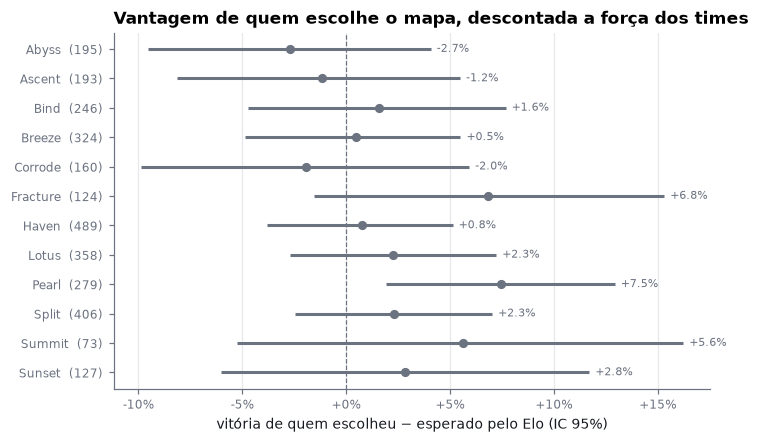

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.2))
e = by_map.excess_over_elo
P.forest(ax, [f"{m}  ({n})" for m, n in zip(by_map.map_name, by_map.picks)],
         [x.value for x in e], [x.low for x in e], [x.high for x in e], null=0.0,
         colors=[P.MUTED if v == "inconclusivo" else P.ATTACK for v in by_map.verdict],
         fmt="{:+.1%}")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:+.0%}"))
ax.set_xlabel("vitória de quem escolheu − esperado pelo Elo (IC 95%)")
ax.set_title("Vantagem de quem escolhe o mapa, descontada a força dos times")
plt.show()

### O veto como ele é jogado

Quantas vezes cada mapa foi banido, escolhido ou ficou de decider na janela: a base da visualização
de veto do site (D27).

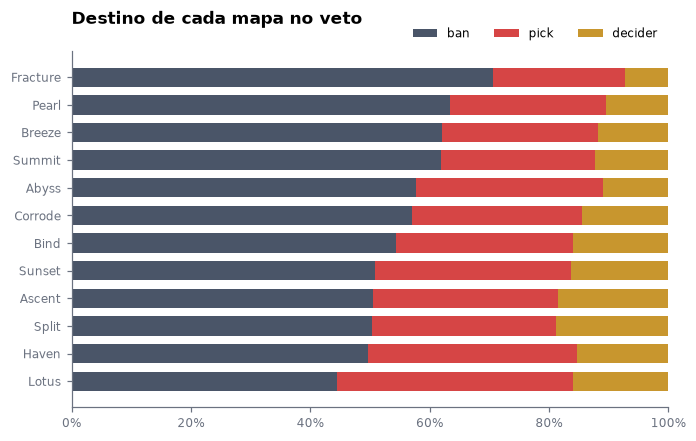

veto_action,ban,pick,decider,total
map_name,,,,
Haven,706,497,217,1420
Split,688,421,258,1367
Breeze,778,326,148,1252
Pearl,690,284,114,1088
Lotus,405,361,145,911
Bind,460,251,135,846
Ascent,318,195,116,629
Abyss,361,197,68,626
Fracture,407,127,42,576


In [4]:
actions = veto["actions"]
counts = actions.pivot_table(index="map_name", columns="veto_action", values="times",
                             aggfunc="sum", fill_value=0)[["ban", "pick", "decider"]]
share = counts.div(counts.sum(axis=1), axis=0).sort_values("ban")
fig, ax = plt.subplots(figsize=(7, 4.2))
left = np.zeros(len(share))
for action, color in [("ban", P.NEUTRAL), ("pick", P.ATTACK), ("decider", P.GOLD)]:
    ax.barh(share.index, share[action], left=left, color=color, label=action, height=0.7)
    left += share[action]
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:.0%}"))
ax.set_xlim(0, 1)
ax.grid(axis="y", visible=False)
ax.legend(ncols=3, loc="lower right", bbox_to_anchor=(1, 1.0))
ax.set_title("Destino de cada mapa no veto", pad=18)
plt.show()
counts.assign(total=counts.sum(axis=1)).sort_values("total", ascending=False)

## Conclusão

In [5]:
sig = by_map[by_map.verdict != "inconclusivo"]
paired = veto["paired"]
paired_text = (
    "o IC exclui 50%: existe vantagem mensurável de quem escolhe"
    if paired.excludes(0.5) else
    "o IC inclui 50%: **inconclusivo** — não dá para afirmar que escolher o mapa dá vantagem"
)
display(Markdown(f"""
- **Pareado:** quem escolhe vence **{paired.text(percent=True)}** dos próprios picks em
  {veto['paired_matches']} séries; {paired_text}.
- **Por mapa:** {len(sig)} de {len(by_map)} mapas com efeito significativo depois de Holm
  ({", ".join(sig.map_name) or "nenhum"}). O maior desvio bruto é
  {by_map.loc[by_map.excess_over_elo.map(lambda x: x.value).idxmax(), "map_name"]}, sem sobreviver à
  correção.
- Se existe, a vantagem de escolher é de poucos pontos percentuais: menor do que a amostra da
  janela consegue separar. Inconclusivo é resultado.
"""))


- **Pareado:** quem escolhe vence **51,5% (IC 95% 49,8%–53,1%)** dos próprios picks em
  1405 séries; o IC inclui 50%: **inconclusivo** — não dá para afirmar que escolher o mapa dá vantagem.
- **Por mapa:** 0 de 12 mapas com efeito significativo depois de Holm
  (nenhum). O maior desvio bruto é
  Pearl, sem sobreviver à
  correção.
- Se existe, a vantagem de escolher é de poucos pontos percentuais: menor do que a amostra da
  janela consegue separar. Inconclusivo é resultado.
